# Function 6: pooled cohort model predictions

**Side quest — 20 October 2026.** A copy of the [Week 4 notebook](../../../../../notebooks/Function_6/Week_04/model_predictions.ipynb),
using **28 observations**: 20 shared initial points,
3 confirmed own returns and **5 additional peer records**.
The methods, target treatments and search settings are retained. Peer data are
published reports, not independently verified portal returns. See the
[dataset audit](../../../dataset-audit.json) for exact sources and exclusions.

Week 4 has already been submitted. Any original coverage plan is a historical
reference; any newly calculated suggestion here is hypothetical. This pooled
snapshot includes records collected later, so its validation is not a forecast
made before the original Week 3 return. Query-budget numbers refer to the
original start of Week 4 and confer no additional evaluation allowance.


## Function description and modelling clues

**Course description, paraphrased.** Balance five ingredient settings against recipe penalties for flavour, consistency, calories, waste and cost. The lesson describes a negative score improving towards zero.

Source: [Mini-lesson 12.8: function descriptions](https://classroom.emeritus.org/courses/18642/modules/items/3237303), reviewed
20 October 2026. The notes below interpret the fixed cohort snapshot collected
on that date. Peer outputs are published reports, not independently verified
portal returns. Every official objective remains maximisation of signed y.

Read the [cohort evidence and exploration clues](observation_review.ipynb) alongside these model results.

### What the fitted comparisons add

The GP has held-out **RMSE 0.2475**, versus **0.6119** for the mean baseline,
about a **60% reduction**. Its retrospective held-out prediction of the latest
query was **-0.5574**, against **-0.5514** observed. This supports useful
structure without resolving the exact best recipe.

Every tested exploration weight chooses x5 = 0 in the current candidate pool,
but the other settings change. This is sensitivity within one fitted model,
not independent evidence that zero x5 is optimal. The standard UCB candidate
has mean **-0.5084**, below the **-0.3787** incumbent, and SD **0.1762**; it is
an information-gathering proposal. Keep all five inputs available and use local
comparisons to separate their effects. The sign interpretation above is unchanged.

Held-out comparisons and method selection use the same small snapshot; they are not independent final-test results. The notes do not change targets, settings or query policies.


In [1]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import LeaveOneOut, cross_val_predict
import sys

shared_dir = Path.cwd().resolve().parents[1] / "Shared"
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from coverage_helpers import make_coverage_space
from coverage_cache import compare_coverage_batches
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS


In [2]:
# Data and output paths for this week's notebook.
# Start the kernel with this notebook's folder as its working directory.
week_dir = Path.cwd().resolve()
full_data_path = week_dir / "observations.csv"

if not (week_dir / "model_predictions.ipynb").is_file() or not full_data_path.is_file():
    raise FileNotFoundError(
        "Run this notebook with its own folder as the working directory; "
        "model_predictions.ipynb and observations.csv must be together."
    )

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)

In [3]:
# Basic data load
print(f"Loading data from: {full_data_path}")
data = pd.read_csv(full_data_path, float_precision="round_trip")

Loading data from: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\side-quests\cohort-2026-10-20\notebooks\Function_6\Week_04\observations.csv


In [4]:
# Column inspection
columns = data.columns
print("Columns: ", columns)

Columns:  Index(['observation_id', 'source_round', 'x1', 'x2', 'x3', 'x4', 'x5', 'y'], dtype='str')


In [5]:
# Where we pray for good data, aka checking for nulls
print (data.isna().sum())

observation_id    0
source_round      0
x1                0
x2                0
x3                0
x4                0
x5                0
y                 0
dtype: int64


In [6]:
# Splitting our data into inputs X and outputs y
output_column = "y"
# The course names inputs x1, x2, ...; preserve their CSV column order.
input_columns = [
    name for name in data.columns
    if name.startswith("x") and name[1:].isdigit()
]

#print("Input columns: ", input_columns)
#print("Output column: ", output_column)

X = data[input_columns]
y = data[output_column]

#print("The inputs are given by :")
#print(X.head())
#print("The outputs are given by :")
#print(y[:5])


In [7]:
# Set up leave-one-out validation for the model comparisons that follow.
cross_validation = LeaveOneOut()
number_of_folds = cross_validation.get_n_splits(X)

print(f"Validation folds: {number_of_folds}")
print(f"Training observations per fold: {len(X) - 1}")
print("Validation observations per fold: 1")

Validation folds: 28
Training observations per fold: 27
Validation observations per fold: 1


In [8]:
# Identify the one new observation in this week's accumulated data.
latest_round = int(data["source_round"].max())
latest_indices = data.index[data["source_round"].eq(latest_round)]
if latest_round == 0 or len(latest_indices) != 1:
    raise ValueError("This weekly comparison expects one latest returned observation.")
latest_index = latest_indices[0]
latest_position = X.index.get_loc(latest_index)
latest_output = float(y.loc[latest_index])
other_observations = data["source_round"].lt(latest_round).to_numpy()

print(f"Latest observation: {data.loc[latest_index, 'observation_id']}")
print(f"Latest output: {latest_output:.6f}")
print(f"Previous best: {y.loc[data['source_round'].lt(latest_round)].max():.6f}")
print("Maximise the original output: less negative is better. Zero is not an established upper bound.")
data.loc[[latest_index], ["observation_id", *input_columns, output_column]]

Latest observation: round-03
Latest output: -0.551379
Previous best: -0.378691
Maximise the original output: less negative is better. Zero is not an established upper bound.


,observation_id,x1,x2,x3,x4,x5,y
27,round-03,0.361714,0.068821,0.707704,0.97754,0.103049,-0.551379


In [9]:
# Establish a mean-prediction benchmark using leave-one-out validation.
baseline_model = DummyRegressor(strategy="mean")

baseline_predictions = cross_val_predict(
    baseline_model,
    X,
    y,
    cv=cross_validation,
)

baseline_rmse = root_mean_squared_error(y, baseline_predictions)

print(f"Baseline RMSE: {baseline_rmse:.4f}")

Baseline RMSE: 0.6119


In [10]:
# Evaluate whether linear input effects improve on the mean baseline.
linear_model = LinearRegression()

linear_predictions = cross_val_predict(
    linear_model,
    X,
    y,
    cv=cross_validation,
)

linear_rmse = root_mean_squared_error(y, linear_predictions)
linear_improvement = 1 - linear_rmse / baseline_rmse

print(f"Mean baseline RMSE: {baseline_rmse:.4f}")
print(f"Linear regression RMSE: {linear_rmse:.4f}")
print(f"RMSE reduction against baseline: {linear_improvement:.1%}")

Mean baseline RMSE: 0.6119
Linear regression RMSE: 0.3433
RMSE reduction against baseline: 43.9%


In [11]:
# Evaluate linear regression with a penalty on large coefficients.
ridge_model = Ridge(alpha=1.0)

ridge_predictions = cross_val_predict(
    ridge_model,
    X,
    y,
    cv=cross_validation,
)

ridge_rmse = root_mean_squared_error(y, ridge_predictions)
ridge_improvement = 1 - ridge_rmse / baseline_rmse

print(f"Ridge regression RMSE: {ridge_rmse:.4f}")
print(f"RMSE reduction against baseline: {ridge_improvement:.1%}")

Ridge regression RMSE: 0.3328
RMSE reduction against baseline: 45.6%


In [12]:
# Evaluate a model that can capture curved input-output relationships.
kernel_ridge_model = KernelRidge(
    alpha=0.1,
    kernel="rbf",
    gamma=1.0,
)

kernel_ridge_predictions = cross_val_predict(
    kernel_ridge_model,
    X,
    y,
    cv=cross_validation,
)

kernel_ridge_rmse = root_mean_squared_error(y, kernel_ridge_predictions)
kernel_ridge_improvement = 1 - kernel_ridge_rmse / baseline_rmse

print(f"Kernel ridge regression RMSE: {kernel_ridge_rmse:.4f}")
print(f"RMSE reduction against baseline: {kernel_ridge_improvement:.1%}")

Kernel ridge regression RMSE: 0.4517
RMSE reduction against baseline: 26.2%


In [13]:
# Evaluate a Gaussian process on the original output scale, as in Function 4.
# Normalisation and kernel fitting happen inside each training fold.
# Assume noise SD is 10% of training output SD; the true noise level is unknown.
noise_fraction = 0.10

gaussian_process_model = GaussianProcessRegressor(
    kernel=ConstantKernel(1.0, (0.01, 100.0)) * RBF(
        length_scale=0.3,
        length_scale_bounds=(0.03, 2.0),
    ),
    alpha=noise_fraction ** 2,
    normalize_y=True,
    n_restarts_optimizer=3,
    random_state=42,
)
gaussian_process_predictions = cross_val_predict(
    gaussian_process_model, X, y, cv=cross_validation,
)
gaussian_process_rmse = root_mean_squared_error(y, gaussian_process_predictions)
print(f"Gaussian-process RMSE: {gaussian_process_rmse:.4f}")
print(f"RMSE reduction against baseline: {1 - gaussian_process_rmse / baseline_rmse:.1%}")

Gaussian-process RMSE: 0.2475
RMSE reduction against baseline: 59.5%


In [14]:
# Compare every model in the same original output units, retaining all observations.
models = {
    "Mean baseline": baseline_model,
    "Linear regression": linear_model,
    "Ridge": ridge_model,
    "Kernel ridge": kernel_ridge_model,
    "Gaussian process": gaussian_process_model,
}
held_out_predictions = {
    "Mean baseline": baseline_predictions,
    "Linear regression": linear_predictions,
    "Ridge": ridge_predictions,
    "Kernel ridge": kernel_ridge_predictions,
    "Gaussian process": gaussian_process_predictions,
}
comparison_rows = []
for name, predictions in held_out_predictions.items():
    error = root_mean_squared_error(y, predictions)
    comparison_rows.append({
        "Model": name,
        "LOO RMSE": error,
        "LOO MAE": mean_absolute_error(y, predictions),
        "RMSE reduction (%)": 100 * (1 - error / baseline_rmse),
    })
model_comparison = pd.DataFrame(comparison_rows).sort_values("LOO RMSE").reset_index(drop=True)
print("RMSE gives large errors more weight; MAE reports average absolute error.")
print(f"All models use the same {len(y)} leave-one-out folds and all observations are retained.")
model_comparison.round(4)

RMSE gives large errors more weight; MAE reports average absolute error.
All models use the same 28 leave-one-out folds and all observations are retained.


,Model,LOO RMSE,LOO MAE,RMSE reduction (%)
0,Gaussian process,0.2475,0.1787,59.5450
1,Ridge,0.3328,0.2684,45.6113
2,Linear regression,0.3433,0.2752,43.8946
3,Kernel ridge,0.4517,0.3568,26.1871
4,Mean baseline,0.6119,0.4954,0.0000


In [15]:
# Inspect the latest-result fold: train on earlier observations and predict the new one.
# Model settings were chosen for this analysis, so this is a retrospective check.
# The other-row metric below uses folds that include the latest observation in training.
latest_rows = []
for name, predictions in held_out_predictions.items():
    residuals = predictions - y.to_numpy()
    latest_prediction = float(predictions[latest_position])
    latest_error = latest_prediction - latest_output
    latest_rows.append({
        "Model": name,
        "Latest held-out prediction": latest_prediction,
        "Latest error": latest_error,
        "Latest absolute error (%)": 100 * abs(latest_error) / abs(latest_output),
        "Latest share of squared error (%)": 100 * latest_error ** 2 / np.sum(residuals ** 2),
        "Other rows LOO RMSE": root_mean_squared_error(
            y.to_numpy()[other_observations], predictions[other_observations],
        ),
    })
latest_prediction_review = pd.DataFrame(latest_rows).sort_values("Latest absolute error (%)").reset_index(drop=True)
print(f"Actual latest output: {latest_output:.6f}")
print(f"Each prediction of this latest output used only the {other_observations.sum()} earlier observations.")
print("Other rows LOO RMSE excludes this row from scoring, not from their training folds.")
latest_prediction_review.round(4)

Actual latest output: -0.551379
Each prediction of this latest output used only the 27 earlier observations.
Other rows LOO RMSE excludes this row from scoring, not from their training folds.


,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,Gaussian process,-0.5574,-0.0060,1.0913,0.0021,0.2521
1,Linear regression,-0.4502,0.1012,18.3528,0.3103,0.3491
2,Ridge,-0.6573,-0.1060,19.2158,0.3620,0.3383
3,Kernel ridge,-0.4392,0.1122,20.3494,0.2204,0.4594
4,Mean baseline,-1.3514,-0.8000,145.0877,6.1043,0.6038


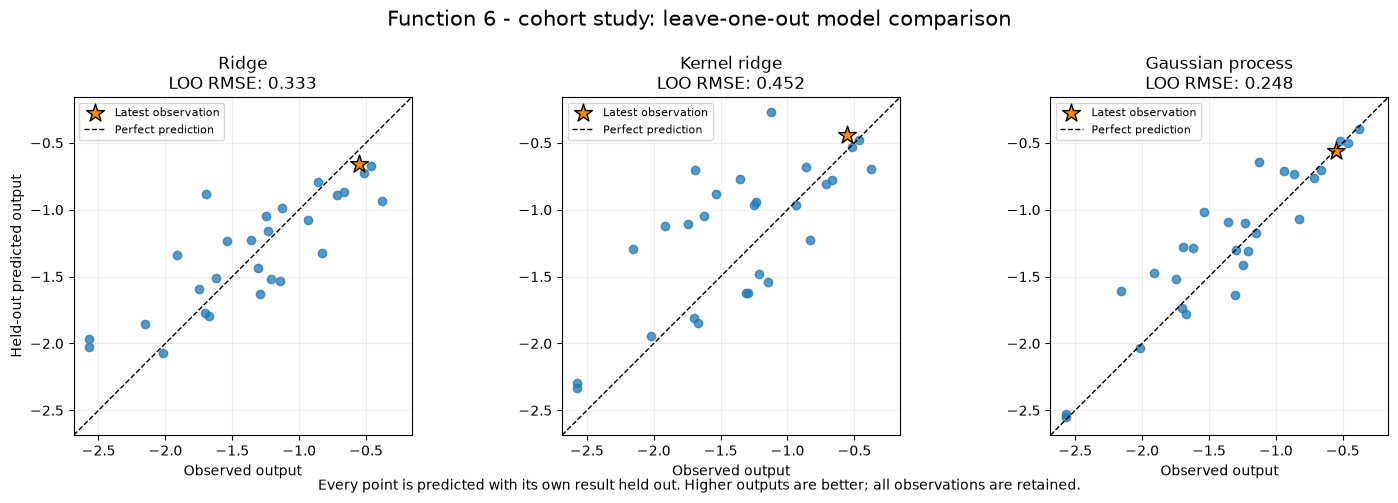

In [16]:
# Compare the linear and nonlinear alternatives on the same output scale.
plot_models = ["Ridge", "Kernel ridge", "Gaussian process"]
plot_values = np.concatenate([
    y.to_numpy(), *(held_out_predictions[name] for name in plot_models),
])
plot_padding = 0.05 * np.ptp(plot_values)
plot_limits = (
    float(plot_values.min() - plot_padding),
    float(plot_values.max() + plot_padding),
)

fig, axes = plt.subplots(1, len(plot_models), figsize=(15, 5))
for ax, name in zip(axes, plot_models):
    predictions = held_out_predictions[name]
    ax.scatter(y.to_numpy()[other_observations], predictions[other_observations], alpha=0.75)
    ax.scatter(
        latest_output, predictions[latest_position], marker="*", s=180,
        color="darkorange", edgecolor="black", label="Latest observation",
    )
    ax.plot(plot_limits, plot_limits, "k--", linewidth=1, label="Perfect prediction")
    ax.set(
        xlim=plot_limits, ylim=plot_limits, xlabel="Observed output",
        title=f"{name}\nLOO RMSE: {root_mean_squared_error(y, predictions):.3f}",
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("Held-out predicted output")
fig.suptitle("Function 6 - cohort study: leave-one-out model comparison", fontsize=15)
fig.text(
    0.5, 0.02,
    "Every point is predicted with its own result held out. Higher outputs are better; all observations are retained.",
    ha="center", fontsize=10,
)
fig.tight_layout(rect=(0, 0.055, 1, 0.95))
fig.savefig(figures / "model-comparison-validation.png", dpi=160, bbox_inches="tight")
plt.show()

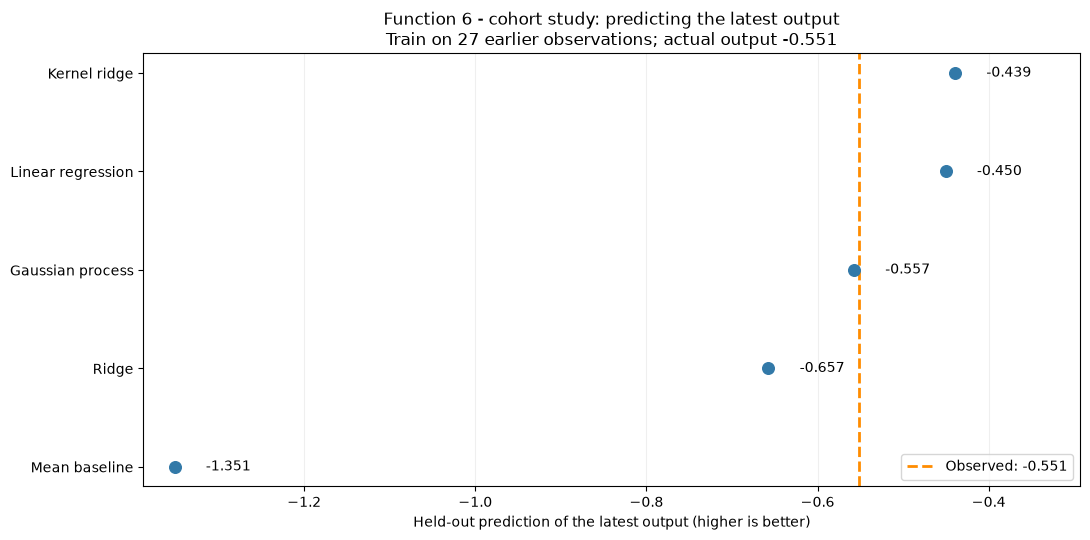

In [17]:
# Compare each model's held-out prediction with the latest result.
latest_chart = latest_prediction_review.sort_values("Latest held-out prediction", ascending=False)
fig, ax = plt.subplots(figsize=(11, 5.5))
positions = np.arange(len(latest_chart))
values = latest_chart["Latest held-out prediction"].to_numpy()
ax.scatter(values, positions, color="#3279a8", s=70, zorder=3)
ax.set_yticks(positions, latest_chart["Model"])
ax.invert_yaxis()
ax.axvline(
    latest_output, color="darkorange", linewidth=2, linestyle="--",
    label=f"Observed: {latest_output:.3f}",
)
chart_min = min(latest_output, values.min())
chart_max = max(latest_output, values.max())
chart_padding = 0.04 * (chart_max - chart_min)
for position, value in zip(positions, values):
    ax.text(value + chart_padding, position, f"{value:.3f}", va="center", fontsize=10)
ax.set_xlim(chart_min - chart_padding, chart_max + 4 * chart_padding)
ax.set_xlabel("Held-out prediction of the latest output (higher is better)")
ax.set_title(
    f"Function 6 - cohort study: predicting the latest output\n"
    f"Train on {other_observations.sum()} earlier observations; actual output {latest_output:.3f}"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(figures / "latest-output-predictions.png", dpi=160, bbox_inches="tight")
plt.show()

In [18]:
# Check fitting with the new result included, separately from held-out performance.
# These fitted values are training predictions and are not validation evidence.
fitted_models = {}
fit_review_rows = []
for name, model in models.items():
    fitted_model = clone(model).fit(X, y)
    fitted_models[name] = fitted_model
    fitted_latest = float(fitted_model.predict(X.loc[[latest_index]])[0])
    fit_review_rows.append({
        "Model": name,
        "Observed latest output": latest_output,
        "Held-out prediction": held_out_predictions[name][latest_position],
        "Fitted prediction (training)": fitted_latest,
    })
print("Including the new output may let a model fit it closely; this does not mean it predicted it in advance.")
pd.DataFrame(fit_review_rows).round(4)

Including the new output may let a model fit it closely; this does not mean it predicted it in advance.


,Model,Observed latest output,Held-out prediction,Fitted prediction (training)
0,Mean baseline,-0.5514,-1.3514,-1.3228
1,Linear regression,-0.5514,-0.4502,-0.4673
2,Ridge,-0.5514,-0.6573,-0.6433
3,Kernel ridge,-0.5514,-0.4392,-0.4883
4,Gaussian process,-0.5514,-0.5574,-0.5518


In [19]:
# Summarise the evidence before moving on to query selection.
lowest_rmse = model_comparison.iloc[0]
lowest_mae = model_comparison.loc[model_comparison["LOO MAE"].idxmin()]
closest_latest = latest_prediction_review.iloc[0]
lowest_rmse_latest = latest_prediction_review.loc[
    latest_prediction_review["Model"].eq(lowest_rmse["Model"])
].iloc[0]

print(f"Lowest overall LOO RMSE: {lowest_rmse['Model']} ({lowest_rmse['LOO RMSE']:.4f}).")
print(f"RMSE reduction against mean baseline: {lowest_rmse['RMSE reduction (%)']:.1f}%.")
print(f"Lowest overall LOO MAE: {lowest_mae['Model']} ({lowest_mae['LOO MAE']:.4f}).")
print(
    f"Closest prediction of the latest held-out result: {closest_latest['Model']}, "
    f"{closest_latest['Latest held-out prediction']:.4f} versus actual {latest_output:.4f}."
)
print(f"Its absolute error on that result: {closest_latest['Latest absolute error (%)']:.1f}%.")
print(
    f"The latest result contributes {lowest_rmse_latest['Latest share of squared error (%)']:.1f}% "
    "of the lowest-RMSE model's total held-out squared error."
)
print("Overall prediction error and ability to locate a better maximum are different assessments.")
print("This comparison does not establish the location or value of the global maximum.")
print("Model comparison is complete; query selection follows below.")

Lowest overall LOO RMSE: Gaussian process (0.2475).
RMSE reduction against mean baseline: 59.5%.
Lowest overall LOO MAE: Gaussian process (0.1787).
Closest prediction of the latest held-out result: Gaussian process, -0.5574 versus actual -0.5514.
Its absolute error on that result: 1.1%.
The latest result contributes 0.0% of the lowest-RMSE model's total held-out squared error.
Overall prediction error and ability to locate a better maximum are different assessments.
This comparison does not establish the location or value of the global maximum.
Model comparison is complete; query selection follows below.


In [20]:
# Retain the Week 2 Gaussian-process choice; review the updated validation above.
selected_model = fitted_models["Gaussian process"]

print(f"Selected model: {type(selected_model).__name__}")
print(f"Observations used for the final fit: {len(X)}")
print(f"Fitted kernel: {selected_model.kernel_}")
print(f"Assumed noise SD: {noise_fraction * y.std(ddof=0):.4f} output units")
print("Use one model-guided query, then reassess after its output returns.")

Selected model: GaussianProcessRegressor
Observations used for the final fit: 28
Fitted kernel: 0.942**2 * RBF(length_scale=0.551)
Assumed noise SD: 0.0590 output units
Use one model-guided query, then reassess after its output returns.


In [21]:
# Build a broad Sobol candidate space, keeping all five inputs free.
candidate_inputs = pd.DataFrame(
    make_coverage_space(X.shape[1], power=14, seed=42),
    columns=input_columns,
)

# Retain the low-x5 boundary candidates motivated by the Week 2 observations.
# This is an additional candidate source, not an assumption that the maximum lies there.
# The remaining inputs still vary across their full ranges.
boundary_inputs = candidate_inputs.copy()
boundary_inputs["x5"] = 0.0

# Compare with an independently optimised single-query coverage alternative.
single_coverage_comparison = compare_coverage_batches(
    existing=X,
    cache_dir=week_dir / ".coverage-cache",
    max_queries=1,
)
single_coverage_inputs = pd.DataFrame(
    single_coverage_comparison["proposed_batches"][1],
    columns=input_columns,
)

candidate_inputs = pd.concat([
    candidate_inputs.assign(candidate_source="Full input space"),
    boundary_inputs.assign(candidate_source="Low x5 boundary"),
    single_coverage_inputs.assign(candidate_source="Single coverage query"),
], ignore_index=True).drop_duplicates(subset=input_columns).reset_index(drop=True)

coverage_before = single_coverage_comparison["results"][0]["max_distance"]
coverage_after = single_coverage_comparison["results"][1]["max_distance"]
print(f"Candidate locations before excluding observed inputs: {len(candidate_inputs):,}")
print(f"The single pure-coverage query reduces the assessed worst gap by {1 - coverage_after / coverage_before:.1%}.")
print("That geometric reduction does not measure improvement in the observed output.")

q=0: computed and saved


q=1: computed and saved


Candidate locations before excluding observed inputs: 32,801
The single pure-coverage query reduces the assessed worst gap by 12.1%.
That geometric reduction does not measure improvement in the observed output.


In [22]:
# Rank candidates by the same UCB rule used for Function 4.
# UCB = posterior mean + exploration weight * posterior standard deviation.
# Posterior SD measures uncertainty in the fitted function, excluding new observation noise.
# The acquisition score is not a predicted output or a calibrated confidence guarantee.
exploration_weight = 1.96
observed_coordinates = set(map(tuple, X.round(6).to_numpy()))
is_new_candidate = [
    tuple(row) not in observed_coordinates
    for row in candidate_inputs[input_columns].round(6).to_numpy()
]
bayesian_candidates = candidate_inputs.loc[is_new_candidate].copy().reset_index(drop=True)

candidate_mean, candidate_uncertainty = selected_model.predict(
    bayesian_candidates[input_columns], return_std=True,
)
bayesian_candidates["posterior_mean"] = candidate_mean
bayesian_candidates["posterior_std"] = candidate_uncertainty
bayesian_candidates["ucb"] = candidate_mean + exploration_weight * candidate_uncertainty
bayesian_candidates = bayesian_candidates.sort_values("ucb", ascending=False).reset_index(drop=True)
recommended_candidate = bayesian_candidates.iloc[0]

# Show the strongest candidate from each route, including pure coverage.
candidate_comparison = bayesian_candidates.loc[
    bayesian_candidates.groupby("candidate_source")["ucb"].idxmax()
].sort_values("ucb", ascending=False)
print(f"Unobserved candidate locations: {len(bayesian_candidates):,}")
print(f"Best observed output: {y.max():.6f}")
print(f"Exploration weight: {exploration_weight}")
print("Best individual alternative from each candidate source:")
candidate_comparison.round(6)

Unobserved candidate locations: 32,799
Best observed output: -0.378691
Exploration weight: 1.96
Best individual alternative from each candidate source:


,x1,x2,x3,x4,x5,candidate_source,posterior_mean,posterior_std,ucb
0,0.372969,0.060881,0.494780,0.695324,0.000000,Low x5 boundary,-0.508366,0.176244,-0.162928
41,0.408614,0.165122,0.463635,0.625161,0.020670,Full input space,-0.477615,0.144163,-0.195056
19490,0.509338,0.008871,0.499746,0.008556,0.490914,Single coverage query,-1.521579,0.351747,-0.832154


In [23]:
# Summarise one proposed query and check sensitivity to the exploration weight.
# The maximum is over our sampled candidates, not a proven global maximum.
next_query = recommended_candidate[input_columns].astype(float).round(6)
next_query_inputs = pd.DataFrame([next_query.to_numpy()], columns=input_columns)
next_mean, next_std = selected_model.predict(next_query_inputs, return_std=True)

if not np.isfinite(next_query.to_numpy()).all() or not next_query.between(0, 0.999999).all():
    raise ValueError("The proposed query is outside the allowed input space.")
if tuple(next_query) in observed_coordinates:
    raise ValueError("The proposed query has already been observed.")

print("Proposed next query (input-column order):")
print(", ".join(f"{name}={value:.6f}" for name, value in next_query.items()))
print("Portal input: " + "-".join(f"{value:.6f}" for value in next_query))
print(f"Candidate source: {recommended_candidate['candidate_source']}")
print("Reason: highest sampled UCB score across the full space, low-x5 boundary and single-coverage alternative.")
print(f"Best observed output: {y.max():.6f}")
print(f"Predicted output at the proposed query: {next_mean[0]:.6f}")
print(f"Posterior standard deviation: {next_std[0]:.6f}")
print(f"Predicted improvement from the mean: {next_mean[0] - y.max():.6f}")
print(f"UCB acquisition score: {next_mean[0] + exploration_weight * next_std[0]:.6f}")
if next_mean[0] <= y.max():
    print("This query is model-guided exploration: its predicted mean is below the current best.")
    print("It earns its place through uncertainty about a potentially better region, rather than predicted mean improvement.")
else:
    print("This query combines predicted mean improvement with exploration of model uncertainty.")
print("Decision: use this one adaptive model-guided query, then review the returned output before planning another.")
print("The prediction remains conditional on the fitted kernel, noise assumption and sampled candidate space.")
print("This is a model-based proposal, not a guaranteed improvement or a submission.")

# Check noise assumptions at this same proposed location; do not refit selected_model.
# This is a sensitivity check, not a search for the best noise setting.
noise_sensitivity = []
for assumed_noise_fraction in [0.03, noise_fraction, 0.30]:
    if assumed_noise_fraction == noise_fraction:
        sensitivity_model = selected_model
    else:
        sensitivity_model = clone(selected_model).set_params(alpha=assumed_noise_fraction ** 2)
        sensitivity_model.fit(X, y)
    sensitivity_mean, sensitivity_std = sensitivity_model.predict(next_query_inputs, return_std=True)
    noise_sensitivity.append({
        "Assumed noise fraction": assumed_noise_fraction,
        "Predicted output": sensitivity_mean[0],
        "Posterior SD": sensitivity_std[0],
        "Predicted mean improvement": sensitivity_mean[0] - y.max(),
    })

print("Predictions at the proposed query under different noise assumptions:")
print(pd.DataFrame(noise_sensitivity).round(6).to_string(index=False))
print("The noise fraction is an assumption; these checks do not establish the true noise level.")

exploration_sensitivity = []
for weight in [0.0, 1.0, 1.96, 3.0]:
    scores = bayesian_candidates["posterior_mean"] + weight * bayesian_candidates["posterior_std"]
    candidate = bayesian_candidates.loc[scores.idxmax()]
    exploration_sensitivity.append({
        "Exploration weight": weight,
        **candidate[input_columns].to_dict(),
        "Predicted output": candidate["posterior_mean"],
        "Posterior SD": candidate["posterior_std"],
    })

pure_exploitation = exploration_sensitivity[0]
pure_mean_gain = pure_exploitation["Predicted output"] - y.max()
print(f"The best sampled mean predicts {pure_exploitation['Predicted output']:.6f}: gain {pure_mean_gain:.6f} over the best observed output.")
if abs(pure_mean_gain) < pure_exploitation["Posterior SD"]:
    print("That mean difference is smaller than its posterior SD; pure exploitation offers no clear predicted gain.")
print("Selected locations under different exploration weights (0 means pure exploitation):")
pd.DataFrame(exploration_sensitivity).round(6)

Proposed next query (input-column order):
x1=0.372969, x2=0.060881, x3=0.494780, x4=0.695324, x5=0.000000
Portal input: 0.372969-0.060881-0.494780-0.695324-0.000000
Candidate source: Low x5 boundary
Reason: highest sampled UCB score across the full space, low-x5 boundary and single-coverage alternative.
Best observed output: -0.378691
Predicted output at the proposed query: -0.508366
Posterior standard deviation: 0.176244
Predicted improvement from the mean: -0.129675
UCB acquisition score: -0.162928
This query is model-guided exploration: its predicted mean is below the current best.
It earns its place through uncertainty about a potentially better region, rather than predicted mean improvement.
Decision: use this one adaptive model-guided query, then review the returned output before planning another.
The prediction remains conditional on the fitted kernel, noise assumption and sampled candidate space.
This is a model-based proposal, not a guaranteed improvement or a submission.
Pred

,Exploration weight,x1,x2,x3,x4,x5,Predicted output,Posterior SD
0,0.00,0.379920,0.252295,0.567527,0.711475,0.0,-0.383406,0.074394
1,1.00,0.415611,0.228887,0.530829,0.717517,0.0,-0.389317,0.086615
2,1.96,0.372969,0.060881,0.494780,0.695324,0.0,-0.508366,0.176244
3,3.00,0.020153,0.008842,0.278387,0.148995,0.0,-1.241845,0.472736


## Evidence for model-led queries

Use **GP RMSE / mean-baseline RMSE** as the main comparison: below 1 means better
held-out predictions than the baseline; 0.2 means one fifth of its error. The
existing model table reports the equivalent percentage reduction. This measures
predictive usefulness on the observed data, not the fraction of the input space explored.

Also check how many different locations the tested exploration weights select.
One location means this choice is stable across those weights for this candidate
sample and fitted model. Several locations mean the exploration trade-off still
changes the decision. Retain the noise-sensitivity check above.

The query budget provides context, not a confidence score. These checks do not
establish that exploration is complete or that the global optimum has been found;
GP uncertainty depends on its [kernel and noise assumptions](https://scikit-learn.org/stable/modules/gaussian_process.html).


In [24]:
# Reuse the validation and sensitivity results already calculated above: no new fits.
relative_gp_error = gaussian_process_rmse / baseline_rmse if baseline_rmse > 0 else None
weight_choices = pd.DataFrame(exploration_sensitivity)
distinct_choices = len(weight_choices[input_columns].round(6).drop_duplicates())

model_evidence = pd.DataFrame([
    {
        "Check": "GP / mean-baseline held-out RMSE",
        "Result": f"{relative_gp_error:.3f} (1.000 = baseline)" if relative_gp_error is not None else "Undefined: baseline error is zero",
    },
    {
        "Check": "RMSE in output units: GP / baseline",
        "Result": f"{gaussian_process_rmse:.4f} / {baseline_rmse:.4f}",
    },
    {
        "Check": "Distinct proposed locations across exploration weights",
        "Result": f"{distinct_choices} across {len(weight_choices)} tested weights (six-decimal inputs)",
    },
    {
        "Check": "Queries available from the start of this week",
        "Result": f"{remaining_queries(week_dir)} of the {TOTAL_QUERY_WEEKS}-query course allowance",
    },
])
model_evidence


,Check,Result
0,GP / mean-baseline held-out RMSE,0.405 (1.000 = baseline)
1,RMSE in output units: GP / baseline,0.2475 / 0.6119
2,Distinct proposed locations across exploration...,4 across 4 tested weights (six-decimal inputs)
3,Queries available from the start of this week,10 of the 13-query course allowance


## Side-quest proposal

The calculated input is an exploratory proposal from the pooled data. The official Week 4 input has already been submitted and is unchanged.